In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("Fake and Real News Dataset.csv")

In [4]:
df.head()

,Unnamed: 0,Title,clean_text,News_Type
0,0,internet shutdown planned,internet shutdown planned internet shutdown pl...,Fake
1,1,medical breakthrough in disease treatment,medical breakthrough disease treatment medical...,Real
2,2,crops failing everywhere,crops failing everywhere crops failing everywh...,Fake
3,3,athlete breaks national record,athlete breaks national record athlete breaks ...,Real
4,4,innocent person jailed,innocent person jailed innocent person jailed ...,Fake


In [7]:
df.head(1)

pandas.DataFrame

In [4]:
df.tail()

,Unnamed: 0,Title,clean_text,News_Type
299995,299995,olympics preparations underway,olympics preparations underway infrastructure ...,Real
299996,299996,art exhibition showcases talent,art exhibition showcases talent contemporary w...,Real
299997,299997,cyber attack imminent,cyber attack imminent false warning causes panic,Fake
299998,299998,currency worthless soon,currency worthless soon unverified claims caus...,Fake
299999,299999,public safety infrastructure improved,public safety infrastructure improved modern e...,Real


In [5]:
df.shape

(300000, 4)

In [6]:
df.columns

Index(['Unnamed: 0', 'Title', 'clean_text', 'News_Type'], dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   Unnamed: 0  300000 non-null  int64
 1   Title       300000 non-null  str  
 2   clean_text  300000 non-null  str  
 3   News_Type   300000 non-null  str  
dtypes: int64(1), str(3)
memory usage: 37.9 MB


In [8]:
df.describe()

,Unnamed: 0
count,300000.000000
mean,149999.500000
std,86602.684716
min,0.000000
25%,74999.750000
50%,149999.500000
75%,224999.250000
max,299999.000000


In [9]:
df.dtypes

Unnamed: 0    int64
Title           str
clean_text      str
News_Type       str
dtype: object

In [10]:
df.isnull().sum()

Unnamed: 0    0
Title         0
clean_text    0
News_Type     0
dtype: int64

In [11]:
(df.isnull().sum()/len(df))*100

Unnamed: 0    0.0
Title         0.0
clean_text    0.0
News_Type     0.0
dtype: float64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df[df.duplicated()]

,Unnamed: 0,Title,clean_text,News_Type


In [14]:
df = df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
## Drop Unnecessary Column

In [17]:
df['Title'] = df['Title'].str.lower()

In [18]:
df['clean_text'] = df['clean_text'].str.lower()

In [19]:
df['Title'] = df['Title'].str.replace(r'[^a-zA-Z\s]', '', regex=True)

In [20]:
df['clean_text'] = df['clean_text'].str.replace(r'[^a-zA-Z\s]', '', regex=True)

In [21]:
df['Title'] = df['Title'].str.replace(r'\s+', ' ', regex=True).str.strip()

In [22]:
df['clean_text'] = df['clean_text'].str.replace(r'\s+', ' ', regex=True).str.strip()


In [23]:
df[['Title', 'clean_text', 'News_Type']].head(10)

,Title,clean_text,News_Type
0,internet shutdown planned,internet shutdown planned false warnings cause...,Fake
1,medical breakthrough in disease treatment,medical breakthrough disease treatment researc...,Real
2,crops failing everywhere,crops failing everywhere exaggerated reports c...,Fake
3,athlete breaks national record,athlete breaks national record outstanding per...,Real
4,innocent person jailed,innocent person jailed unverified claims injus...,Fake
5,device causes health problems,device causes health problems debunked theory ...,Fake
6,environmental collapse imminent,environmental collapse imminent false predicti...,Fake
7,environmental protection laws strengthened,environmental protection laws strengthened str...,Real
8,universities hiding truth,universities hiding truth conspiracy theories ...,Fake
9,climate change hoax claimed,climate change hoax claimed misinformation spr...,Fake


In [24]:
import sys

print(sys.executable)

D:\Coding\ML_Projects\venv\Scripts\python.exe


In [25]:
import nltk

print(nltk.__version__)

3.10.3


In [26]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\rh940\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rh940\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rh940\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [29]:
from nltk.tokenize import word_tokenize

df['Title_tokens'] = df['Title'].fillna('').apply(word_tokenize)
df['clean_text_tokens'] = df['clean_text'].fillna('').apply(word_tokenize)

In [30]:
df[['Title', 'Title_tokens', 'clean_text','clean_text_tokens']].head()

,Title,Title_tokens,clean_text,clean_text_tokens
0,internet shutdown planned,"[internet, shutdown, planned]",internet shutdown planned false warnings cause...,"[internet, shutdown, planned, false, warnings,..."
1,medical breakthrough in disease treatment,"[medical, breakthrough, in, disease, treatment]",medical breakthrough disease treatment researc...,"[medical, breakthrough, disease, treatment, re..."
2,crops failing everywhere,"[crops, failing, everywhere]",crops failing everywhere exaggerated reports c...,"[crops, failing, everywhere, exaggerated, repo..."
3,athlete breaks national record,"[athlete, breaks, national, record]",athlete breaks national record outstanding per...,"[athlete, breaks, national, record, outstandin..."
4,innocent person jailed,"[innocent, person, jailed]",innocent person jailed unverified claims injus...,"[innocent, person, jailed, unverified, claims,..."


In [31]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rh940\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [32]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

In [33]:
df['Title_tokens'] = df['Title_tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)
df['clean_text_tokens'] = df['clean_text_tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)

In [34]:
df['tokens'] = df['Title_tokens'] + df['clean_text_tokens']

In [35]:
df['clean_text'] = df['tokens'].apply(lambda x: ' '.join(x))

In [36]:
df[['Title', 'clean_text' ]].head(10)

,Title,clean_text
0,internet shutdown planned,internet shutdown planned internet shutdown pl...
1,medical breakthrough in disease treatment,medical breakthrough disease treatment medical...
2,crops failing everywhere,crops failing everywhere crops failing everywh...
3,athlete breaks national record,athlete breaks national record athlete breaks ...
4,innocent person jailed,innocent person jailed innocent person jailed ...
5,device causes health problems,device causes health problems device causes he...
6,environmental collapse imminent,environmental collapse imminent environmental ...
7,environmental protection laws strengthened,environmental protection laws strengthened env...
8,universities hiding truth,universities hiding truth universities hiding ...
9,climate change hoax claimed,climate change hoax claimed climate change hoa...


In [37]:
new_df = df[['Title', 'clean_text', 'News_Type']]
new_df.head()

,Title,clean_text,News_Type
0,internet shutdown planned,internet shutdown planned internet shutdown pl...,Fake
1,medical breakthrough in disease treatment,medical breakthrough disease treatment medical...,Real
2,crops failing everywhere,crops failing everywhere crops failing everywh...,Fake
3,athlete breaks national record,athlete breaks national record athlete breaks ...,Real
4,innocent person jailed,innocent person jailed innocent person jailed ...,Fake


In [38]:
new_df.to_csv('Fake and Real News Dataset.csv')

In [39]:
X = df['clean_text']
y = df['News_Type']

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [41]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 240000
Testing samples: 60000


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
) 

In [43]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [44]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(240000, 1673)
(60000, 1673)


In [45]:
#  logistic regression 

In [46]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver='liblinear'
)

lr_model.fit(X_train_tfidf, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [48]:
y_pred = lr_model.predict(X_test_tfidf)

print(y_pred[:20])

['Real' 'Fake' 'Real' 'Real' 'Fake' 'Real' 'Real' 'Fake' 'Real' 'Fake'
 'Real' 'Real' 'Fake' 'Real' 'Fake' 'Real' 'Fake' 'Real' 'Real' 'Fake']


In [49]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy*100)

Accuracy: 100.0


In [50]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00     23987
        Real       1.00      1.00      1.00     36013

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



In [51]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[23987     0]
 [    0 36013]]


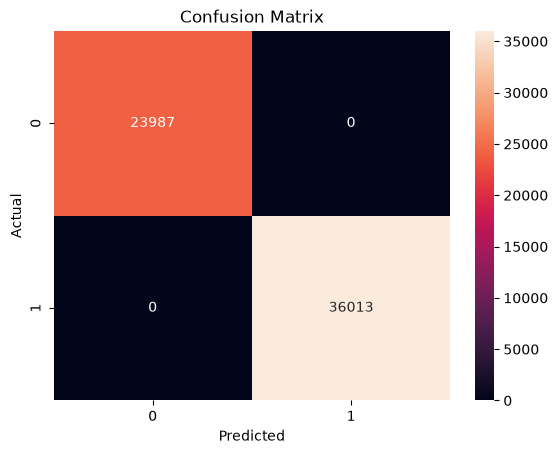

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [53]:
#  naive bayes model

In [54]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[ 95946.,144054.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.92,-0.51]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U4](2,)","['Fake','Real']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 1673)","[[407.66,240.77,240.77,..., 0. , 0. , 0. ], [ 0. , 0. , 0. ,...,329.22,603.51,603.51]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 1673)","[[ -6.72, -7.24, -7.24,...,-12.73,-12.73,-12.73], [-13.25,-13.25,-13.25,..., -7.45, -6.84, -6.84]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1673


In [55]:
nb_pred = nb_model.predict(X_test_tfidf)

In [56]:
print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_pred))

print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 1.0
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00     23987
        Real       1.00      1.00      1.00     36013

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



In [57]:
## SVM model

In [60]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [61]:
svm_pred = svm_model.predict(X_test_tfidf)

In [62]:
print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred))

print(classification_report(y_test, svm_pred))

SVM Accuracy: 1.0
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00     23987
        Real       1.00      1.00      1.00     36013

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



In [63]:
lr_accuracy = accuracy_score(y_test, y_pred)
nb_accuracy = accuracy_score(y_test, nb_pred)
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Logistic Regression:", lr_accuracy)
print("Naive Bayes:", nb_accuracy)
print("Linear SVM:", svm_accuracy)

Logistic Regression: 1.0
Naive Bayes: 1.0
Linear SVM: 1.0


In [64]:
results = {
    "Logistic Regression": lr_accuracy,
    "Naive Bayes": nb_accuracy,
    "Linear SVM": svm_accuracy
}

print(results)

{'Logistic Regression': 1.0, 'Naive Bayes': 1.0, 'Linear SVM': 1.0}


In [65]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

lr_train_acc = accuracy_score(y_train, lr_model.predict(X_train_tfidf))
nb_train_acc = accuracy_score(y_train, nb_model.predict(X_train_tfidf))
svm_train_acc = accuracy_score(y_train, svm_model.predict(X_train_tfidf))

print("Logistic Regression:", lr_train_acc)
print("Naive Bayes:", nb_train_acc)
print("Linear SVM:", svm_train_acc)


Logistic Regression: 1.0
Naive Bayes: 1.0
Linear SVM: 1.0


In [66]:
import joblib

In [68]:
joblib.dump(lr_model, 'nlp_model.joblib')

['nlp_model.joblib']

In [69]:
joblib.dump(lr_model, 'nlp_model.pkl')

['nlp_model.pkl']

In [70]:
joblib.dump(tfidf, 'nlp_vectorizer.joblib')

['nlp_vectorizer.joblib']

In [71]:
joblib.dump(tfidf, 'nlp_vectorizer.pkl')

['nlp_vectorizer.pkl']

In [72]:
loaded_model = joblib.load('nlp_model.joblib')
loaded_vectorizer = joblib.load('nlp_vectorizer.joblib

In [73]:
new_title = "Medical breakthrough"
new_full_text = "internet shutdown planned false warnings cause concern"

new_text = [new_title + " " + new_full_text]

X_new = loaded_vectorizer.transform(new_text)
prediction = loaded_model.predict(X_new)

print("Prediction:", prediction)

Prediction: ['Fake']
